In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
data=pd.read_csv("/content/Employee.csv")
data.head()


,Company,Age,Salary,Place,Country,Gender
0,TCS,20.0,NaN,Chennai,India,0
1,Infosys,30.0,NaN,Mumbai,India,0
2,TCS,35.0,2300.0,Calcutta,India,0
3,Infosys,40.0,3000.0,Delhi,India,0
4,TCS,23.0,4000.0,Mumbai,India,0


In [2]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Company  140 non-null    object 
 1   Age      130 non-null    float64
 2   Salary   124 non-null    float64
 3   Place    134 non-null    object 
 4   Country  148 non-null    object 
 5   Gender   148 non-null    int64  
dtypes: float64(2), int64(1), object(3)
memory usage: 7.1+ KB


In [3]:
data.shape

(148, 6)

In [4]:
data.describe()

,Age,Salary,Gender
count,130.000000,124.000000,148.000000
mean,30.484615,5312.467742,0.222973
std,11.096640,2573.764683,0.417654
min,0.000000,1089.000000,0.000000
25%,22.000000,3030.000000,0.000000
50%,32.500000,5000.000000,0.000000
75%,37.750000,8000.000000,0.000000
max,54.000000,9876.000000,1.000000


In [5]:
data.columns

Index(['Company', 'Age', 'Salary', 'Place', 'Country', 'Gender'], dtype='object')

In [6]:
cols=['Company', 'Age', 'Salary', 'Place', 'Country', 'Gender']
for i in cols:
  print("Unique values in column",i,"=",data[i].unique())
  print("Total number of unique values in column",i,"=",data[i].nunique())
  data['Company'] = data['Company'].replace('Tata Consultancy Services','TCS')


Unique values in column Company = ['TCS' 'Infosys' 'CTS' nan 'Tata Consultancy Services' 'Congnizant'
 'Infosys Pvt Lmt']
Total number of unique values in column Company = 6
Unique values in column Age = [20. 30. 35. 40. 23. nan 34. 45. 18. 22. 32. 37. 50. 21. 46. 36. 26. 41.
 24. 25. 43. 19. 38. 51. 31. 44. 33. 17.  0. 54.]
Total number of unique values in column Age = 29
Unique values in column Salary = [  nan 2300. 3000. 4000. 5000. 6000. 7000. 8000. 9000. 1089. 1234. 3030.
 3045. 3184. 4824. 5835. 7084. 8943. 8345. 9284. 9876. 2034. 7654. 2934.
 4034. 5034. 8202. 9024. 4345. 6544. 6543. 3234. 4324. 5435. 5555. 8787.
 3454. 5654. 5009. 5098. 3033.]
Total number of unique values in column Salary = 40
Unique values in column Place = ['Chennai' 'Mumbai' 'Calcutta' 'Delhi' 'Podicherry' 'Cochin' nan 'Noida'
 'Hyderabad' 'Bhopal' 'Nagpur' 'Pune']
Total number of unique values in column Place = 11
Unique values in column Country = ['India']
Total number of unique values in column Country =

In [7]:
data["Age"].unique()
data['Age'] = data['Age'].replace('0', 'Nan')

In [8]:
data.isnull().sum()/len(data)*100
s=['Age', 'Salary']
for i in s:
  mean=data[i].mean()
  data[i].fillna(mean,inplace=True)
g=['Company','Place']
for b in g:
  mode=data[b].mode()[0]
  data[b].fillna(mode,inplace=True)





/tmp/ipykernel_16721/4127561450.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data[i].fillna(mean,inplace=True)
/tmp/ipykernel_16721/4127561450.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.met

In [9]:
print(data.duplicated().sum())
data.drop_duplicates(inplace=True)

4


In [10]:
data=data.drop(columns=["Country"])
print(data.head())

   Company   Age       Salary     Place  Gender
0      TCS  20.0  5312.467742   Chennai       0
1  Infosys  30.0  5312.467742    Mumbai       0
2      TCS  35.0  2300.000000  Calcutta       0
3  Infosys  40.0  3000.000000     Delhi       0
4      TCS  23.0  4000.000000    Mumbai       0


<Axes: ylabel='Salary'>

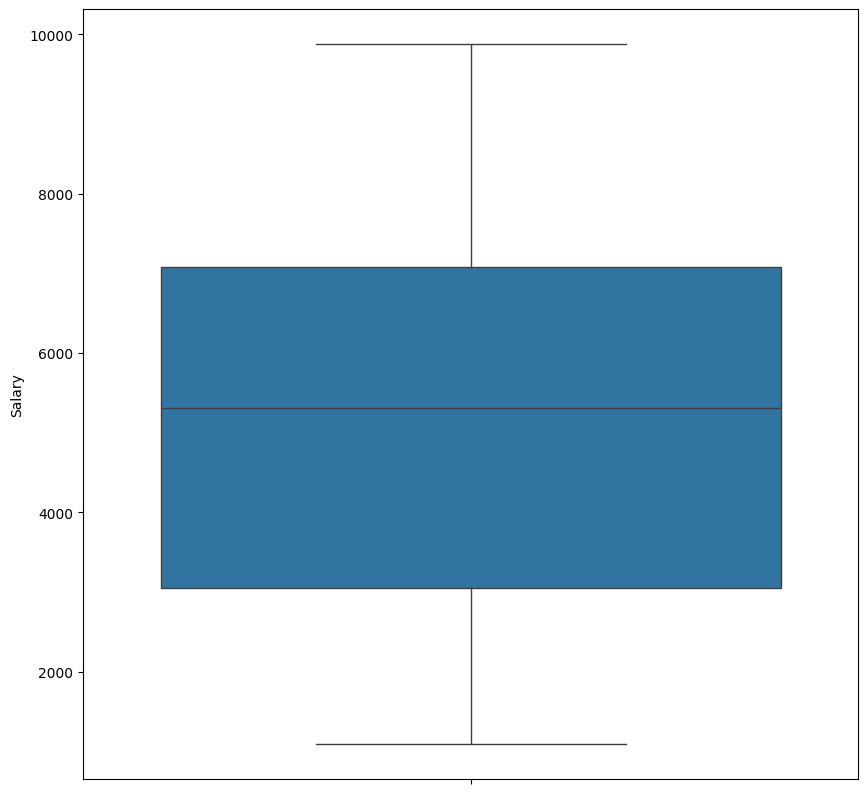

In [11]:
plt.figure(figsize=(10,10))
sns.boxplot(data["Salary"])

In [12]:
print(data.isnull().sum()/len(data)*100)

Company    0.0
Age        0.0
Salary     0.0
Place      0.0
Gender     0.0
dtype: float64


In [13]:
data.duplicated().sum()

np.int64(0)

In [14]:
data.columns

Index(['Company', 'Age', 'Salary', 'Place', 'Gender'], dtype='object')

In [15]:
q1,q2,q3=np.percentile(data['Salary'],[25,50,75])
print(q1)
print(q2)
print(q3)
iqr=q3-q1
lower=q1-1.5*iqr
upper=q3+1.5*iqr
outlier=[]
for i in data["Salary"]:
  if i<lower or i>upper:
    outlier.append(i)
print(outlier)

3045.0
5312.467741935484
7084.0
[]


In [16]:
data["Age"].unique()

array([20.        , 30.        , 35.        , 40.        , 23.        ,
       30.48461538, 34.        , 45.        , 18.        , 22.        ,
       32.        , 37.        , 50.        , 21.        , 46.        ,
       36.        , 26.        , 41.        , 24.        , 25.        ,
       43.        , 19.        , 38.        , 51.        , 31.        ,
       44.        , 33.        , 17.        ,  0.        , 54.        ])

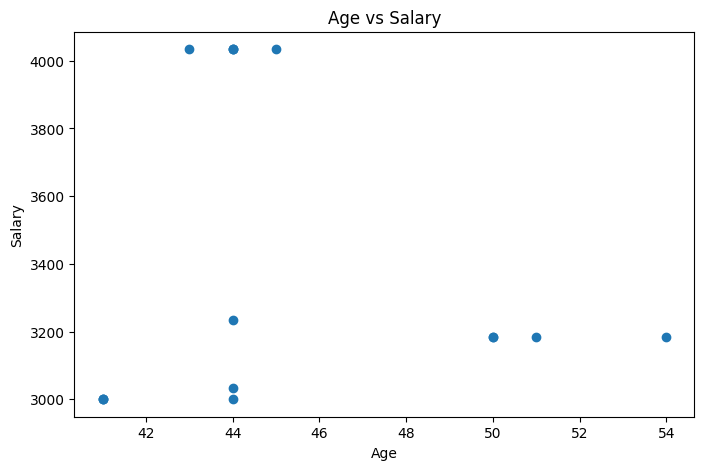

In [17]:
# Filtering the data
a = data[(data['Age'] > 40) & (data['Salary'] < 5000)]

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.scatter(a['Age'], a['Salary'])

plt.xlabel('Age')
plt.ylabel('Salary')
plt.title('Age vs Salary')

plt.show()

Place
Mumbai        48
Calcutta      32
Chennai       14
Delhi         14
Cochin        13
Noida          8
Hyderabad      8
Podicherry     3
Pune           2
Bhopal         1
Nagpur         1
Name: count, dtype: int64


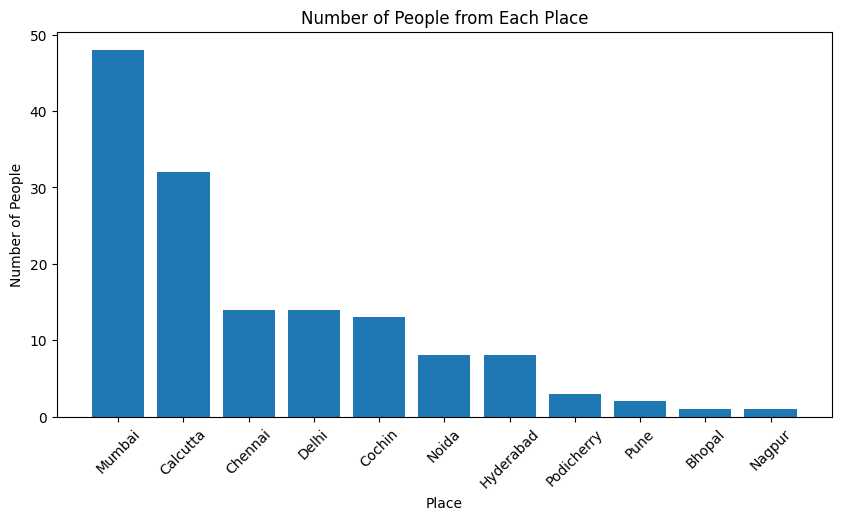

In [18]:
place_count = data['Place'].value_counts()

print(place_count)
plt.figure(figsize=(10,5))

plt.bar(place_count.index, place_count.values)

plt.xlabel('Place')
plt.ylabel('Number of People')
plt.title('Number of People from Each Place')

plt.xticks(rotation=45)

plt.show()

In [19]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

cols = ['Gender']

for i in cols:
    data[i] = le.fit_transform(data[i])

print(data.head())

   Company   Age       Salary     Place  Gender
0      TCS  20.0  5312.467742   Chennai       0
1  Infosys  30.0  5312.467742    Mumbai       0
2      TCS  35.0  2300.000000  Calcutta       0
3  Infosys  40.0  3000.000000     Delhi       0
4      TCS  23.0  4000.000000    Mumbai       0


In [21]:
data = pd.get_dummies(data, columns=['Company', 'Place'], dtype=int)

print(data.head())

    Age       Salary  Gender  Company_CTS  Company_Congnizant  \
0  20.0  5312.467742       0            0                   0   
1  30.0  5312.467742       0            0                   0   
2  35.0  2300.000000       0            0                   0   
3  40.0  3000.000000       0            0                   0   
4  23.0  4000.000000       0            0                   0   

   Company_Infosys  Company_Infosys Pvt Lmt  Company_TCS  Place_Bhopal  \
0                0                        0            1             0   
1                1                        0            0             0   
2                0                        0            1             0   
3                1                        0            0             0   
4                0                        0            1             0   

   Place_Calcutta  Place_Chennai  Place_Cochin  Place_Delhi  Place_Hyderabad  \
0               0              1             0            0                0   
1   

In [22]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

data_scaled = sc.fit_transform(data)

data_scaled = pd.DataFrame(data_scaled, columns=data.columns)

print(data_scaled.head())

        Age    Salary    Gender  Company_CTS  Company_Congnizant  \
0 -1.012082  0.010324 -0.534522    -0.566658           -0.118678   
1 -0.050254  0.010324 -0.534522    -0.566658           -0.118678   
2  0.430659 -1.266072 -0.534522    -0.566658           -0.118678   
3  0.911573 -0.969479 -0.534522    -0.566658           -0.118678   
4 -0.723534 -0.545775 -0.534522    -0.566658           -0.118678   

   Company_Infosys  Company_Infosys Pvt Lmt  Company_TCS  Place_Bhopal  \
0        -0.652490                -0.118678     1.150035     -0.083624   
1         1.532592                -0.118678    -0.869539     -0.083624   
2        -0.652490                -0.118678     1.150035     -0.083624   
3         1.532592                -0.118678    -0.869539     -0.083624   
4        -0.652490                -0.118678     1.150035     -0.083624   

   Place_Calcutta  Place_Chennai  Place_Cochin  Place_Delhi  Place_Hyderabad  \
0       -0.534522       3.047247     -0.315018    -0.328165       

In [23]:
from sklearn.preprocessing import MinMaxScaler

ms = MinMaxScaler()

data_minmax = ms.fit_transform(data)

data_minmax = pd.DataFrame(data_minmax, columns=data.columns)

print(data_minmax.head())

        Age    Salary  Gender  Company_CTS  Company_Congnizant  \
0  0.370370  0.480650     0.0          0.0                 0.0   
1  0.555556  0.480650     0.0          0.0                 0.0   
2  0.648148  0.137817     0.0          0.0                 0.0   
3  0.740741  0.217480     0.0          0.0                 0.0   
4  0.425926  0.331285     0.0          0.0                 0.0   

   Company_Infosys  Company_Infosys Pvt Lmt  Company_TCS  Place_Bhopal  \
0              0.0                      0.0          1.0           0.0   
1              1.0                      0.0          0.0           0.0   
2              0.0                      0.0          1.0           0.0   
3              1.0                      0.0          0.0           0.0   
4              0.0                      0.0          1.0           0.0   

   Place_Calcutta  Place_Chennai  Place_Cochin  Place_Delhi  Place_Hyderabad  \
0             0.0            1.0           0.0          0.0              0.0  